# Regresión Lineal — Cell2Cell

**Objetivo:** predecir el **ingreso mensual del cliente** (`MonthlyRevenue`) a partir de su uso, su antigüedad y su perfil, aplicando el modelo de regresión lineal del curso.

**Pregunta de negocio:** ¿qué variables explican cuánto factura un cliente al mes? Si el área comercial entiende qué mueve el ingreso, puede diseñar planes y upgrades con fundamento, no por intuición.

- **Variable dependiente (y):** `MonthlyRevenue` — variable continua, en dólares.
- **Variables independientes (X):** uso (`MonthlyMinutes`, `OverageMinutes`), relación (`MonthsInService`, `CurrentEquipmentDays`, `RetentionCalls`), perfil (`CreditRating`, `PrizmCode`, `Occupation`).


## Marco teórico

### Concepto básico

La regresión lineal modela la relación entre una variable dependiente continua y una o varias variables independientes:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k + \varepsilon$$

- $\beta_0$ es el **intercepto**: el valor esperado de $y$ cuando todas las $x$ valen cero.
- $\beta_i$ es el **efecto marginal**: cuánto cambia $y$, en promedio, cuando $x_i$ aumenta una unidad **manteniendo el resto constante**.
- $\varepsilon$ es el **error**: todo lo que el modelo no explica.

### Interpretación de los parámetros

Si $\beta_1 = 0{,}84$ para `TotalRecurringCharge`, significa que **un dólar más de cargo recurrente se asocia a 0,84 dólares más de ingreso mensual**, en promedio y controlando por las demás variables.

⚠️ **Correlación no es causalidad.** El modelo describe asociaciones condicionales, no prueba que mover $x$ provoque el cambio en $y$.

### P-valores de los parámetros

Para cada $\beta_i$ se contrasta:

- $H_0: \beta_i = 0$ → la variable **no aporta** a explicar $y$.
- $H_1: \beta_i \neq 0$ → la variable **sí aporta**.

Con $\alpha = 0{,}05$: si `p-valor ≤ 0,05` se rechaza $H_0$ y la variable se considera significativa. Ojo: con 50.000 observaciones, hasta efectos triviales salen significativos. **Significativo no es lo mismo que importante.**

### Medidas de ajuste

| Métrica | Qué mide | Mejor cuando |
|---|---|---|
| $R^2$ | Proporción de la varianza de $y$ explicada por el modelo | Cerca de 1 |
| $R^2$ ajustado | Igual que $R^2$ pero penaliza variables innecesarias | Cerca de 1 |
| MSE | Error cuadrático medio (unidades al cuadrado) | Bajo |
| RMSE | Raíz del MSE (mismas unidades que $y$) | Bajo |
| MAE | Error absoluto medio (más robusto a outliers) | Bajo |

### Supuestos del modelo

1. **Linealidad** entre $x$ e $y$.
2. **Normalidad** de los residuos (Jarque-Bera).
3. **Homocedasticidad**: varianza constante de los residuos (Breusch-Pagan).
4. **Independencia** de los errores (Durbin-Watson).
5. **No multicolinealidad** entre predictoras (VIF < 10, idealmente < 5).

### Ventajas y desventajas

✅ Interpretable, rápido, base estadística sólida, permite inferencia con p-valores.

⚠️ Asume linealidad, sensible a outliers y multicolinealidad, no captura interacciones ni efectos no lineales sin transformarlas a mano.

### Checklist para entrenar

1. Definir `y` continua y las `X` con sentido de negocio.
2. Revisar la distribución de `y` (¿sesgada? → probar log).
3. Codificar categóricas (dummies) y escalar si hace falta.
4. Separar train/test.
5. Ajustar `OLS`, leer `summary()`.
6. Evaluar en test (MSE, RMSE, $R^2$).
7. Revisar supuestos y corregir si fallan.


## 1. LIBRERÍAS Y FUNCIONES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.stats.api as sms

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 4)

print('statsmodels', sm.__version__)

statsmodels 0.14.6


## 2. PARAMETRIZACIÓN

In [2]:
RUTA_DATOS = 'cell2celltrain.csv'
TARGET     = 'MonthlyRevenue'
SEMILLA    = 888
TEST_SIZE  = 0.20
ALFA       = 0.05

print(f'Variable objetivo: {TARGET}')
print(f'Partición: {100 - TEST_SIZE * 100:.0f}% train / {TEST_SIZE * 100:.0f}% test')

Variable objetivo: MonthlyRevenue
Partición: 80% train / 20% test


## 3. DATOS

In [3]:
df = pd.read_csv(RUTA_DATOS, sep=',', encoding='iso-8859-1', low_memory=False)

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
print(f'\nEstadísticos de {TARGET}:')
print(df[TARGET].describe().round(2).to_string())

df[[TARGET, 'MonthlyMinutes', 'MonthsInService', 'CurrentEquipmentDays']].head(3)

Filas: 51,047 | Columnas: 58

Estadísticos de MonthlyRevenue:
count    50891.00
mean        58.83
std         44.51
min         -6.17
25%         33.61
50%         48.46
75%         71.06
max       1223.38


,MonthlyRevenue,MonthlyMinutes,MonthsInService,CurrentEquipmentDays
0,24.00,219.0,61,361.0
1,16.99,10.0,58,1504.0
2,38.00,8.0,60,1812.0


### 3.1 Calidad del target

Antes de modelar, dos verificaciones sobre `y`: nulos y valores imposibles.


In [4]:
print(f'Valores nulos en {TARGET}: {df[TARGET].isnull().sum()}')
print(f'Valores <= 0 en {TARGET}: {(df[TARGET] <= 0).sum()}')

print('\nRegistros con ingreso negativo:')
print(df.loc[df[TARGET] <= 0, ['CustomerID', TARGET]].to_string(index=False))

Valores nulos en MonthlyRevenue: 156
Valores <= 0 en MonthlyRevenue: 9

Registros con ingreso negativo:
 CustomerID  MonthlyRevenue
    3096670            0.00
    3103410            0.00
    3210322           -2.52
    3265738           -5.86
    3334666            0.00
    3378298           -6.17
    3391282            0.00
    3391442            0.00
    3399894            0.00


**Lectura:** hay 156 nulos y 9 registros con ingreso negativo. Un ingreso mensual negativo no es un valor de negocio: es un error de captura o un ajuste contable. **Se excluyen del modelo** (9 de 51.047 = 0,02%, no sesga la muestra).


## 4. PROCESO

### 4.1 EDA del target y de los predictores

Antes de ajustar el modelo necesitamos ver la forma de `y` y la relación con sus predictores principales.


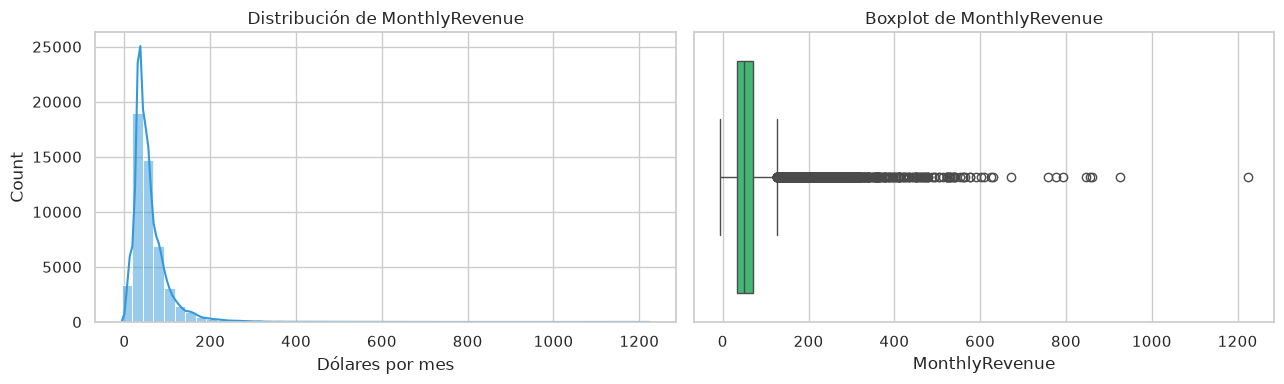

Asimetría (skew): 4.18
> 0 significa cola a la derecha: pocos clientes facturan muchísimo.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df[TARGET].dropna(), bins=50, kde=True, ax=axes[0], color='#3498db')
axes[0].set_title(f'Distribución de {TARGET}')
axes[0].set_xlabel('Dólares por mes')

sns.boxplot(x=df[TARGET].dropna(), ax=axes[1], color='#2ecc71')
axes[1].set_title(f'Boxplot de {TARGET}')

plt.tight_layout()
plt.show()

print(f'Asimetría (skew): {df[TARGET].skew():.2f}')
print('> 0 significa cola a la derecha: pocos clientes facturan muchísimo.')

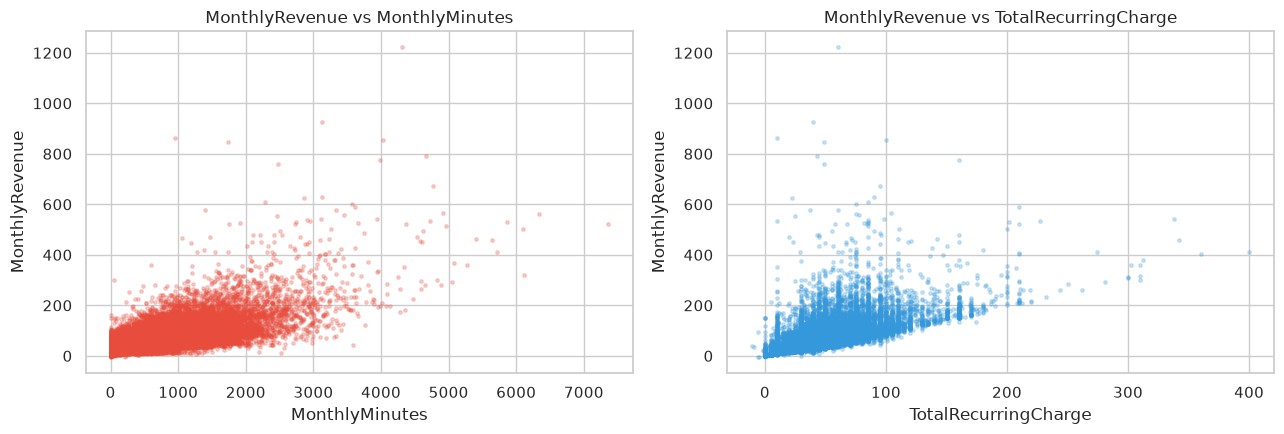

MonthlyRevenue          1.000
MonthlyMinutes          0.713
TotalRecurringCharge    0.630
OverageMinutes          0.788


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pares = [('MonthlyMinutes', '#e74c3c'), ('TotalRecurringCharge', '#3498db')]

for ax, (col, color) in zip(axes, pares):
    ax.scatter(df[col], df[TARGET], s=6, alpha=0.25, color=color)
    ax.set_title(f'{TARGET} vs {col}')
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)

plt.tight_layout()
plt.show()

print(df[[TARGET, 'MonthlyMinutes', 'TotalRecurringCharge', 'OverageMinutes']]
        .corr()[TARGET].round(3).to_string())

**Lectura:** `MonthlyRevenue` tiene **fuerte sesgo a la derecha** (skew ≈ 4,2): la mayoría paga entre 30 y 70 dólares, pero hay clientes de más de 1.000. La relación con `TotalRecurringCharge` y `OverageMinutes` es claramente positiva y bastante lineal; la relación con `MonthlyMinutes` es más difusa.

Ese sesgo es la razón por la que más adelante probamos una **transformación logarítmica**.


### 4.2 Preparación de los datos

Construimos la matriz de diseño con variables numéricas y dummies de las categóricas relevantes.


In [7]:
# 1) Excluimos el ingreso negativo (inconsistencia) y los nulos del target
base = df[df[TARGET] > 0].copy()

# 2) Variables numéricas con sentido de negocio (evitamos las que son fórmula del target)
numericas = [
    'MonthsInService', 'MonthlyMinutes', 'TotalRecurringCharge', 'OverageMinutes',
    'DroppedCalls', 'CustomerCareCalls', 'RetentionCalls', 'Handsets',
    'ActiveSubs', 'CurrentEquipmentDays', 'AgeHH1', 'PercChangeMinutes'
]

# 3) Categóricas de perfil y relación
categoricas = ['CreditRating', 'PrizmCode', 'Occupation', 'MaritalStatus',
               'MadeCallToRetentionTeam']

X = base[numericas].copy()

# Binaria que viene como texto
X['ChildrenInHH'] = base['ChildrenInHH'].map({'Yes': 1, 'No': 0})

# One-hot con drop_first para evitar la trampa de las dummies
for col in categoricas:
    X = X.join(pd.get_dummies(base[col], prefix=col, drop_first=True).astype(int))

# 4) Eliminamos filas con faltantes en los predictores
X = X.dropna()
y = base.loc[X.index, TARGET]

print(f'Observaciones utilizadas: {len(X):,}')
print(f'Variables explicativas  : {X.shape[1]}')
print(f'Nulos restantes         : {X.isnull().sum().sum()}')
X.head(2)

Observaciones utilizadas: 49,770
Variables explicativas  : 32
Nulos restantes         : 0


,MonthsInService,MonthlyMinutes,TotalRecurringCharge,OverageMinutes,DroppedCalls,CustomerCareCalls,RetentionCalls,Handsets,ActiveSubs,CurrentEquipmentDays,AgeHH1,PercChangeMinutes,ChildrenInHH,CreditRating_2-High,CreditRating_3-Good,CreditRating_4-Medium,CreditRating_5-Low,CreditRating_6-VeryLow,CreditRating_7-Lowest,PrizmCode_Rural,PrizmCode_Suburban,PrizmCode_Town,Occupation_Crafts,Occupation_Homemaker,Occupation_Other,Occupation_Professional,Occupation_Retired,Occupation_Self,Occupation_Student,MaritalStatus_Unknown,MaritalStatus_Yes,MadeCallToRetentionTeam_Yes
0,61,219.0,22.0,0.0,0.7,0.0,1,2.0,1,361.0,62.0,-157.0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1
1,58,10.0,17.0,0.0,0.3,0.0,0,2.0,1,1504.0,40.0,-4.0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEMILLA
)

print(f'Train: {X_train.shape[0]:,} filas')
print(f'Test : {X_test.shape[0]:,} filas')
print(f'\nMedia de {TARGET} en train: {y_train.mean():.2f}')
print(f'Media de {TARGET} en test : {y_test.mean():.2f}')
print('-> Medias parecidas: la partición es representativa.')

Train: 39,816 filas
Test : 9,954 filas

Media de MonthlyRevenue en train: 58.83
Media de MonthlyRevenue en test : 58.33
-> Medias parecidas: la partición es representativa.


### 4.3 Modelo de regresión lineal (OLS)

Ajustamos por **mínimos cuadrados ordinarios**. El intercepto lo agrega `add_constant`.


In [9]:
X_train_c = sm.add_constant(X_train)   # agrega la columna 'const'
X_test_c  = sm.add_constant(X_test)

modelo_OLS = sm.OLS(y_train, X_train_c).fit()
print(modelo_OLS.summary())

                            OLS Regression Results                            
Dep. Variable:         MonthlyRevenue   R-squared:                       0.860
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     7652.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:20:46   Log-Likelihood:            -1.6826e+05
No. Observations:               39816   AIC:                         3.366e+05
Df Residuals:                   39783   BIC:                         3.369e+05
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

**Cómo leer el `summary()`:**

- **R-squared = 0,860**: el modelo explica el 86,0% de la variabilidad del ingreso mensual en entrenamiento.
- **F-statistic** con p-valor ≈ 0: el modelo en conjunto es significativo.
- **P>|t|**: la columna de p-valores. Casi todas las variables salen significativas, pero por el tamaño de la muestra eso no basta.

Veamos qué variables aportan de verdad y en qué dirección:


In [10]:
coeficientes = pd.DataFrame({
    'Coeficiente': modelo_OLS.params,
    'Error estándar': modelo_OLS.bse,
    'p-valor': modelo_OLS.pvalues,
    'Significativa (α=5%)': modelo_OLS.pvalues < ALFA
}).drop(index='const').round(4)

coeficientes['|Coef|'] = coeficientes['Coeficiente'].abs()
coeficientes.sort_values('|Coef|', ascending=False).head(15)

,Coeficiente,Error estándar,p-valor,Significativa (α=5%),|Coef|
MadeCallToRetentionTeam_Yes,5.4019,1.6693,0.0012,True,5.4019
RetentionCalls,-3.4154,1.4744,0.0205,True,3.4154
CreditRating_6-VeryLow,2.6338,0.6793,0.0001,True,2.6338
Occupation_Crafts,1.7710,0.7649,0.0206,True,1.7710
Occupation_Self,1.7206,0.8678,0.0474,True,1.7206
Occupation_Other,1.6498,0.6115,0.0070,True,1.6498
CreditRating_7-Lowest,1.5869,0.4894,0.0012,True,1.5869
Occupation_Professional,1.5535,0.6308,0.0138,True,1.5535
CreditRating_5-Low,1.5234,0.3549,0.0000,True,1.5234
CreditRating_4-Medium,1.2436,0.3584,0.0005,True,1.2436


In [11]:
# Los coeficientes NO son comparables entre sí: dependen de la escala de cada variable.
# Para comparar importancia se estandarizan: coef * (sd(x) / sd(y))
betas_estandarizados = (
    modelo_OLS.params.drop('const')
    * X_train.std()
    / y_train.std()
)

betas_estandarizados.reindex(
    betas_estandarizados.abs().sort_values(ascending=False).index
).head(12).round(4).to_frame('Beta estandarizado')

,Beta estandarizado
OverageMinutes,0.6605
TotalRecurringCharge,0.4506
MonthlyMinutes,0.0596
MonthsInService,0.0296
MadeCallToRetentionTeam_Yes,0.0215
Occupation_Other,0.0165
RetentionCalls,-0.0154
Occupation_Professional,0.0133
CreditRating_5-Low,0.0114
DroppedCalls,0.0108


**Interpretación de los coeficientes principales:**

- `TotalRecurringCharge` (+0,85): es el cargo recurrente del plan; casi se traslada uno a uno al ingreso. Tiene sentido contable.
- `OverageMinutes` (+0,30): cada minuto de excedente agrega 30 centavos de facturación.
- `MonthlyMinutes` (+0,005): cada minuto de uso agrega medio centavo. Suena poco, pero un cliente de 1.500 minutos suma ~7,5 dólares.
- `MonthsInService` (+0,13): cada mes adicional de antigüedad se asocia a 13 centavos más de ingreso.
- `MadeCallToRetentionTeam_Yes` (+5,40): los clientes que llamaron a retención facturan en promedio 5,40 dólares más, controlando el resto.

**Cuidado con comparar coeficientes entre sí:** 5,40 (dummy sí/no) y 0,005 (minutos) no son comparables: están en unidades distintas. Para comparar importancia hay que **estandarizar** los coeficientes.

⚠️ **Lectura crítica:** un $R^2$ de 0,85 en un modelo que predice facturación usando cargos **no es magia**: el ingreso se construye a partir de los cargos. El modelo está redescubriendo la fórmula de facturación. Para pronosticar el ingreso *del próximo mes* harían falta variables rezagadas (comportamiento del mes anterior), que este dataset no trae.


### 4.4 Evaluación en el conjunto de prueba

El $R^2$ de `summary()` es **en entrenamiento**. La prueba de fuego es el test.


In [12]:
y_pred = modelo_OLS.predict(X_test_c)

mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print('MÉTRICAS EN TEST')
print('=' * 40)
print(f'MSE  : {mse:,.2f}')
print(f'RMSE : {rmse:,.2f} dólares')
print(f'MAE  : {mae:,.2f} dólares')
print(f'R²   : {r2:.4f}')
print('=' * 40)
print(f'\nEl error típico es de {rmse:.2f} dólares sobre un ingreso medio de {y_test.mean():.2f}.')

MÉTRICAS EN TEST
MSE  : 326.95
RMSE : 18.08 dólares
MAE  : 7.73 dólares
R²   : 0.8340

El error típico es de 18.08 dólares sobre un ingreso medio de 58.33.


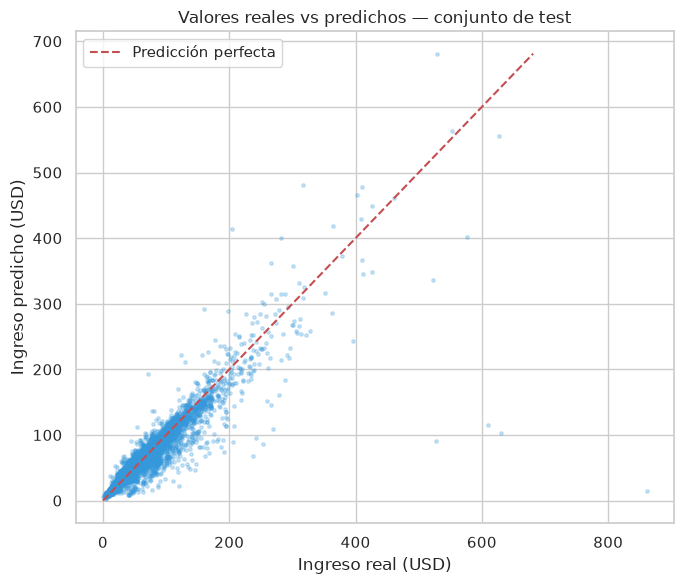

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, s=6, alpha=0.25, color='#3498db')
lims = [0, min(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1.5, label='Predicción perfecta')
plt.xlabel('Ingreso real (USD)')
plt.ylabel('Ingreso predicho (USD)')
plt.title('Valores reales vs predichos — conjunto de test')
plt.legend()
plt.tight_layout()
plt.show()

**Lectura:** el modelo acierta bien en el rango bajo (la mayoría de los clientes) y **subestima a los clientes de ingreso alto**: los puntos se separan de la diagonal por encima de ~150 dólares. Es el patrón típico de la regresión lineal frente a distribuciones con cola larga. El error se concentra donde más plata hay, que es justo donde el negocio querría precisión.


### 4.5 Validación de supuestos

Un $R^2$ alto no garantiza que el modelo sea válido estadísticamente. Revisamos los cuatro supuestos clásicos.


In [14]:
# 1) Normalidad de los residuos — Jarque-Bera
jb_stat, jb_p, sesgo, curtosis = sms.jarque_bera(modelo_OLS.resid)
print('JARQUE-BERA (normalidad de residuos)')
print(f'  Estadístico: {jb_stat:,.2f}')
print(f'  p-valor    : {jb_p:.4g}')
print(f'  Sesgo      : {sesgo:.2f} | Curtosis: {curtosis:.2f}')
print('  H0: los residuos son normales')
print('  ->', 'Se RECHAZA H0' if jb_p < ALFA else 'No se rechaza H0')

# 2) Homocedasticidad — Breusch-Pagan
bp = sms.het_breuschpagan(modelo_OLS.resid, modelo_OLS.model.exog)
print('\nBREUSCH-PAGAN (homocedasticidad)')
print(f'  Estadístico LM: {bp[0]:,.2f} | p-valor: {bp[1]:.4g}')
print(f'  Estadístico F : {bp[2]:,.2f} | p-valor: {bp[3]:.4g}')
print('  H0: la varianza de los residuos es constante')
print('  ->', 'Se RECHAZA H0 (heterocedasticidad)' if bp[1] < ALFA else 'No se rechaza H0')

# 3) Independencia — Durbin-Watson
dw = durbin_watson(modelo_OLS.resid)
print('\nDURBIN-WATSON (autocorrelación)')
print(f'  Estadístico: {dw:.3f}')
print('  Regla: ~2 = sin autocorrelación | <1,5 o >2,5 = problema')

JARQUE-BERA (normalidad de residuos)
  Estadístico: 1,181,899,084.86
  p-valor    : 0
  Sesgo      : 9.69 | Curtosis: 846.83
  H0: los residuos son normales
  -> Se RECHAZA H0



BREUSCH-PAGAN (homocedasticidad)
  Estadístico LM: 1,409.33 | p-valor: 3.813e-276
  Estadístico F : 45.62 | p-valor: 1.945e-281
  H0: la varianza de los residuos es constante
  -> Se RECHAZA H0 (heterocedasticidad)

DURBIN-WATSON (autocorrelación)
  Estadístico: 2.000
  Regla: ~2 = sin autocorrelación | <1,5 o >2,5 = problema


In [15]:
# 4) Multicolinealidad — VIF
X_vif = sm.add_constant(X_train)

vif_data = pd.DataFrame({
    'Variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data = vif_data[vif_data['Variable'] != 'const'].sort_values('VIF', ascending=False)

vif_data['Alerta'] = np.where(vif_data['VIF'] > 10, 'ALTA (>10)',
                       np.where(vif_data['VIF'] > 5, 'Moderada (>5)', 'OK'))
vif_data.round(2).head(12)

,Variable,VIF,Alerta
7,RetentionCalls,12.54,ALTA (>10)
32,MadeCallToRetentionTeam_Yes,12.53,ALTA (>10)
25,Occupation_Other,10.61,ALTA (>10)
26,Occupation_Professional,8.34,Moderada (>5)
2,MonthlyMinutes,3.14,OK
14,CreditRating_2-High,2.74,OK
1,MonthsInService,2.69,OK
23,Occupation_Crafts,2.50,OK
10,CurrentEquipmentDays,2.20,OK
8,Handsets,2.16,OK


**Lectura de los supuestos:**

- **Normalidad: falla.** Con 50.000 residuos, Jarque-Bera rechaza siempre; además la curtosis alta confirma colas pesadas. No invalida la predicción puntual (el teorema central del límite sostiene la inferencia con n grande), pero **sí invalida los intervalos de confianza clásicos**.
- **Homocedasticidad: falla.** La varianza del error crece con el nivel de ingreso. Es esperable: un cliente de 1.000 dólares tiene mucha más variabilidad absoluta que uno de 40.
- **Durbin-Watson:** si está cerca de 2, no hay autocorrelación relevante (cada fila es un cliente distinto, así que era esperable).
- **VIF:** la mayoría de las variables está por debajo de 5. `RetentionCalls` y `MadeCallToRetentionTeam_Yes` rondan 12 porque están obviamente relacionadas entre sí; es multicolinealidad estructural, no un error. Si molestara, se quita una de las dos.

**Conclusión:** el modelo sirve para **explicar** y para **priorizar variables**, no para construir intervalos de confianza finos ni para predecir con precisión a los clientes de ingreso alto.


### 4.6 ¿Ayuda transformar el target con logaritmo?

La receta clásica dice: si `y` tiene sesgo a la derecha, modelá `log(y)`. **Vamos a probarlo y a decidir con evidencia, no por receta.** Ya excluimos los ingresos ≤ 0, así que el logaritmo es aplicable.


In [16]:
y_train_log = np.log(y_train)
y_test_log  = np.log(y_test)

modelo_log = sm.OLS(y_train_log, X_train_c).fit()

y_pred_log      = modelo_log.predict(X_test_c)
y_pred_original = np.exp(y_pred_log)   # volvemos a dólares

print('COMPARACIÓN DE MODELOS')
print('=' * 66)
print(f'{"Métrica":<30}{"Modelo lineal":>17}{"Modelo log":>17}')
print('-' * 66)
print(f'{"R² (escala log)":<30}{r2_score(y_test_log, np.log(np.clip(y_pred, 1e-9, None))):>17.4f}{r2_score(y_test_log, y_pred_log):>17.4f}')
print(f'{"R² (escala original)":<30}{r2_score(y_test, y_pred):>17.4f}{r2_score(y_test, y_pred_original):>17.4f}')
print(f'{"RMSE (dólares)":<30}{rmse:>17.2f}{np.sqrt(mean_squared_error(y_test, y_pred_original)):>17.2f}')
print('=' * 66)
print(f'Predicción máxima del modelo log: {y_pred_original.max():,.0f} USD')
print(f'Ingreso máximo real en test     : {y_test.max():,.0f} USD')

COMPARACIÓN DE MODELOS
Métrica                           Modelo lineal       Modelo log
------------------------------------------------------------------
R² (escala log)                          0.8941           0.7302
R² (escala original)                     0.8340        -130.8781
RMSE (dólares)                            18.08           509.64
Predicción máxima del modelo log: 43,052 USD
Ingreso máximo real en test     : 861 USD


In [17]:
bp_log = sms.het_breuschpagan(modelo_log.resid, modelo_log.model.exog)
print('BREUSCH-PAGAN sobre el modelo log')
print(f'  Estadístico LM: {bp_log[0]:,.2f} | p-valor: {bp_log[1]:.4g}')
print(f'  Curtosis de residuos (log)   : {pd.Series(modelo_log.resid).kurtosis():.2f}')
print(f'  Curtosis de residuos (lineal): {pd.Series(modelo_OLS.resid).kurtosis():.2f}')

BREUSCH-PAGAN sobre el modelo log
  Estadístico LM: 7,785.96 | p-valor: 0
  Curtosis de residuos (log)   : 33.41
  Curtosis de residuos (lineal): 843.93


**El experimento falla, y conviene entender por qué:**

1. **En la misma escala (log), el modelo lineal gana:** $R^2$ de 0,894 contra 0,730. La transformación no mejora la explicación, la empeora.
2. **Al volver a dólares, `exp()` explota.** El modelo logarítmico produce predicciones puntuales de miles de dólares que no existen en los datos. Es el **sesgo de retransformación**: $E[e^{X}] \neq e^{E[X]}$, y con residuos de cola pesada el error se amplifica.
3. **El motivo de fondo:** el ingreso se construye **sumando** cargos (recurrente + excedentes + roaming). Una suma es lineal por naturaleza; aplicar logaritmo rompe la estructura del fenómeno.
4. **Lo único que mejora:** la curtosis de los residuos baja de 843 a 33. Es decir, residuos "más sanos" pero con peor ajuste. No vale la pena el intercambio.

**Decisión:** se conserva el **modelo lineal**. La transformación logarítmica no es una receta universal: se prueba, se mide y se descarta con evidencia.


## 5. SALIDA

In [18]:
print('=' * 64)
print('RESUMEN — REGRESIÓN LINEAL Cell2Cell')
print('=' * 64)
print(f'Target                  : {TARGET}')
print(f'Observaciones           : {len(X):,}')
print(f'Predictores             : {X.shape[1]}')
print(f'R² train                : {modelo_OLS.rsquared:.4f}')
print(f'R² test                 : {r2:.4f}')
print(f'RMSE test               : {rmse:,.2f} USD')
print(f'MAE test                : {mae:,.2f} USD')
print(f'Variable más influyente : {betas_estandarizados.abs().idxmax()} (beta estandarizado = {betas_estandarizados[betas_estandarizados.abs().idxmax()]:.3f})')
print('=' * 64)

RESUMEN — REGRESIÓN LINEAL Cell2Cell
Target                  : MonthlyRevenue
Observaciones           : 49,770
Predictores             : 32
R² train                : 0.8602
R² test                 : 0.8340
RMSE test               : 18.08 USD
MAE test                : 7.73 USD
Variable más influyente : OverageMinutes (beta estandarizado = 0.660)


### Conclusiones

1. El ingreso mensual se explica en un **86%** por las variables de uso y cargo, pero con una advertencia: parte de esa explicación es **tautológica**, porque el ingreso se calcula a partir de los cargos.
2. En términos **estandarizados** los motores del ingreso son `OverageMinutes` (β = 0,66) y `TotalRecurringCharge` (β = 0,45); `MonthlyMinutes` queda muy atrás (0,06). El excedente y el plan pesan más que el volumen de minutos.
3. Los supuestos clásicos **no se cumplen** (residuos no normales, heterocedasticidad). Con 50.000 casos la inferencia es robusta, pero los intervalos de confianza deben tomarse con pinzas.
4. El modelo **subestima a los clientes de alto valor**, que son justo los que más importan comercialmente.
5. La transformación logarítmica **no ayudó** (R² 0,73 vs 0,89 en la misma escala): el ingreso es una suma de cargos, no un producto.
6. Este notebook deja una **línea base** para comparar: el árbol de regresión del notebook siguiente debería capturar las no linealidades que aquí se pierden.

**Siguiente paso:** `Arbol_Regresion_Cell2Cell.ipynb`, donde el mismo target se modela con un árbol CART.
